In [312]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import matplotlib
from scipy.optimize import fsolve
import scipy as sc
from mpmath import findroot
import mpmath


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
import Treat_frequency_study as Treat_frequency_study
importlib.reload(Treat_frequency_study)
from Treat_frequency_study import *




import matplotlib as mpl
mpl.rcParams["font.size"] = 15

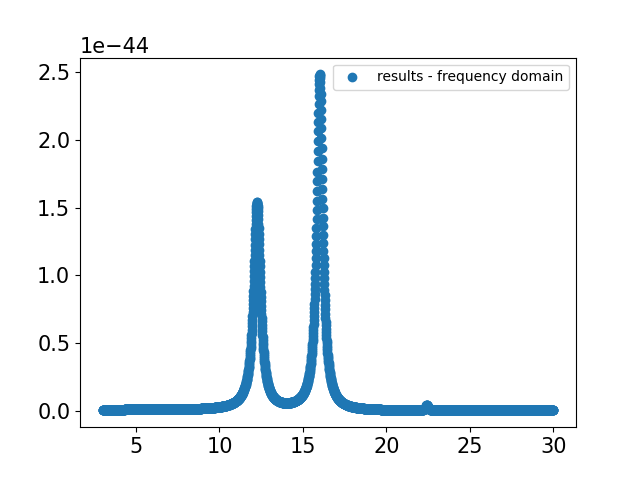

In [313]:
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\Acoustic\Optical study\Thick silica - ND2 zone1'



fname = r'results - frequency domain'
param_list = []
Res_simu = open_COMSOL_results_frequency_study(dir_root, fname, param_list=param_list)

fig, ax = plt.subplots()
for key in Res_simu :
    ax.scatter(Res_simu[key]['freq'], Res_simu[key]['displacement'], label = key)




#ax.set_ylim(-5, 50)
ax.legend(fontsize=10)

In [314]:
## Define parameters

offset = 1e-34

xc1, w1, A1 = 12.32, 1, 1.5e-44
xc2, w2, A2 = 16, 1, 2.5e-44
xc3, w3, A3 = 24, 10, 5e-34

p0 = [offset, xc1, w1, A1, xc2, w2, A2, xc3, w3, A3]
n_modes = 2

for key in Res_simu :
    res = Lorentzian_fitting(Res_simu[key], p0, n_modes = n_modes )

print(globals()['Lorentz' + str(n_modes)])

<function Lorentz2 at 0x000001ECFEB0ADE0>


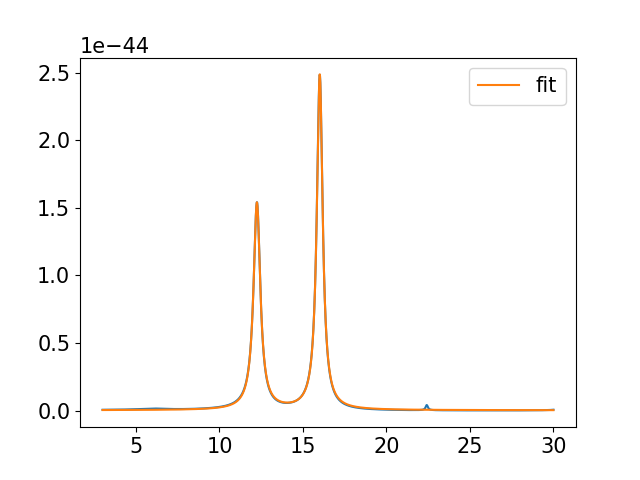

In [315]:
fig, ax = plt.subplots()

for key in Res_simu :
    data = Res_simu[key]
    ax.plot(data['freq'], data['displacement'])
    ax.plot(data['freq'], globals()['Lorentz' + str(n_modes)](data['freq'], *res[0]), label='fit')

ax.legend()

In [ ]:
Modes_fitting = {}
for j in range(n_modes) :
    # Takes into account the offset from the electron peak to compute the phase phi.
    index_coeff = str(j+1)
    Modes_fitting['mode' + str(index_coeff)] = {}

    Modes_fitting['mode' + str(index_coeff)]['f']  = res[0][j*3+1]
    Modes_fitting['mode' + str(index_coeff)]['w']  = res[0][j*3+2]
    Modes_fitting['mode' + str(index_coeff)]['A']  = res[0][j*3+3]
    Modes_fitting['mode' + str(index_coeff)]['Q']  = Modes_fitting['mode' + str(index_coeff)]['f'] / Modes_fitting['mode' + str(index_coeff)]['w']
    Modes_fitting['mode' + str(index_coeff)]['Area']  = Modes_fitting['mode' + str(index_coeff)]['A'] * Modes_fitting['mode' + str(index_coeff)]['w'] *np.pi/2




0
1


In [ ]:
for key in Modes_fitting :
    print(key + ' : f = {:.2f} GHz, Q = {:.2f}, Area = {}'.format(Modes_fitting[key]['f'], Modes_fitting[key]['Q'], Modes_fitting[key]['Area']))

mode1 : f = 12.24 GHz, Q = 24.828956674851746, Area = 1.1850519934028e-44
mode2 : f = 16.01 GHz, Q = 37.720930973223645, Area = 1.6513844790714912e-44
